# Example 4: Columns, walls and a continuous beam

The drawing from papermodels' Example 4 (its notebook is `Example_3.ipynb` in papermodels).
The `J2.0` joist prototype produces the joists `J2.0-0`, `J2.0-1`, ... which bear on `FB2.1`.
`FB2.1` has three supports, so loadtracer analyses it as a continuous beam.

papermodels' `Annotation Legend Entries.ipynb` (in its Example 4) explains the annotation legend
used in these drawings; it is not repeated here.

In [1]:
%matplotlib inline
import sys
import warnings
from decimal import Decimal

import pandas as pd
from papermodels.datatypes.geometry_graph import GeometryGraph
from papermodels.datatypes.joist_models import JoistArrayModel
from loadtracer.load_tracer import LoadTracer

sys.path.insert(0, "..")
from helpers import (
    bottom_members,
    compare_modes,
    load_check,
    load_table,
    occupancies_in,
    quietly,
    reaction_table,
)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_rows = 40

## 1. Build the graph (papermodels)

In [2]:
pdf_path = "sketch_to_scale-vertical-loads.pdf"

In [3]:
graph = GeometryGraph.from_pdf_file(pdf_path, scale=Decimal(1 / 72 * 4))
graph.assign_collector_behaviour(JoistArrayModel, spacing=1.0)

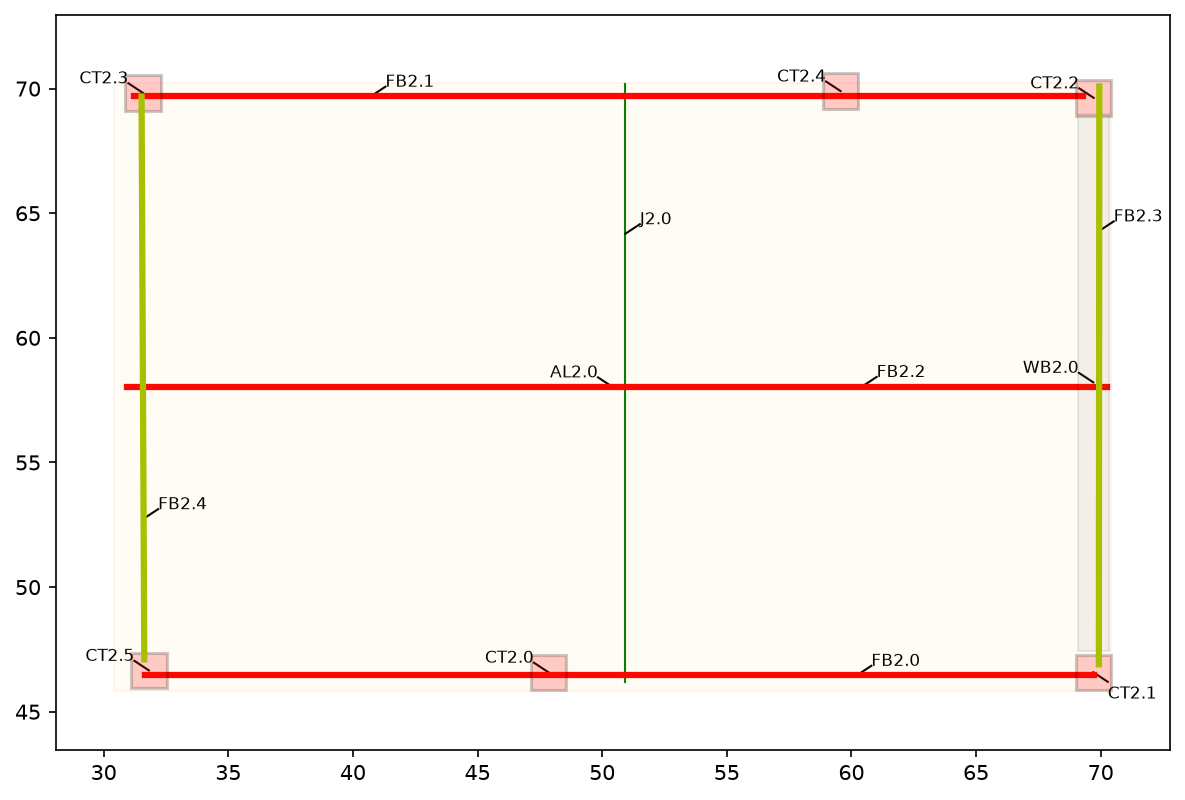

In [4]:
graph.plot_annotations(2)

## 2. Occupancies

loadtracer needs the loads of each occupancy in the drawing, as pressures by load case.
These are the occupancies that the loading areas use:

In [5]:
occupancies_in(graph)

['big stuff', 'residential', 'roof']

The drawing is in feet, so these pressures (psf) give loads in lb/ft and lb.

In [6]:
occupancies = {
    "big stuff": {"D": 50.0, "L": 100.0},
    "residential": {"D": 15.0, "L": 40.0},
    "roof": {"D": 20.0, "S": 35.0},
}

## 3. Run loadtracer

Every element is analysed from the top of the graph down. Only the graph and the occupancies
are needed; element heights and floor elevations are not inputs. `artifacts/` receives the
analysis models (`models.json`) and the reactions (`reaction_forces.json`).

In [7]:
lt = LoadTracer(geometry_graph=graph, occupancies=occupancies)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    quietly(lt.execute_analyses, artifacts_dir="artifacts")

print(f"{len(lt.reactions)} members analysed, {len(lt.errors)} errors")
for w in caught:
    print(f"{type(w.message).__name__}: {w.message}")

127 members analysed, 0 errors


All of the load applied to the building reaches the bottom of the graph:

In [8]:
load_check(lt)

,applied,at the bottom
D,"14,998.28","14,998.28"
L,"28,685.87","28,685.87"
S,"6,563.13","6,563.13"


`lt.issues` lists input that loadtracer corrected so that the rundown could continue
(for example, load drawn past the end of a member, which is moved to the member end):

In [9]:
{tag: issues for tag, issues in lt.issues.items()}

{'WT3.0': ['0.274 of the distributed load from WT4.0 (D) extends past the member end at 0.0; its load was applied as a point load at the end.',
  '0.231 of the distributed load from WT4.0 (D) extends past the member end at 10.58; its load was applied as a point load at the end.',
  '0.274 of the distributed load from WT4.0 (S) extends past the member end at 0.0; its load was applied as a point load at the end.',
  '0.231 of the distributed load from WT4.0 (S) extends past the member end at 10.58; its load was applied as a point load at the end.'],
 'WB0.0': ['0.010 of the distributed load from WT1.0 (D) extends past the member end at 0.0; its load was applied as a point load at the end.',
  '0.010 of the distributed load from WT1.0 (L) extends past the member end at 0.0; its load was applied as a point load at the end.'],
 'WB2.0': ['0.051 of the distributed load from WT3.0 (D) extends past the member end at 0.0; its load was applied as a point load at the end.',
  '0.170 of the distri

## 4. One member, end to end: `FB2.1`

`FB2.1` is continuous over three supports. As a continuous beam with uniform stiffness, the
short end span can have an uplift reaction (a negative value below); simple-span hand
calculations do not show this.

In [10]:
pd.DataFrame(lt.converted_joist_loads("FB2.1"))

,member,array,joists,case,dir,profile,start_loc,end_loc,w_start,w_end,total,max_min_ratio,occupancy,pressure,trib_width_start,trib_width_end,approximate
0,FB2.1,J2.0,20,D,FY,uniform,0.12,18.30,35.09,35.09,638.23,1.01,residential,15.00,2.34,2.34,False
1,FB2.1,J2.0,20,L,FY,uniform,0.12,18.30,93.58,93.58,"1,701.95",1.01,residential,40.00,2.34,2.34,False


The loads on `FB2.1` after expansion, by load case:

In [11]:
load_table(lt, "FB2.1")

,kind,source,case,start,end,w_start / P,w_end,total,profile
0,distributed,J2.0,D,0.12,18.30,35.09,35.09,638.23,uniform
1,distributed,J2.0,L,0.12,18.30,93.58,93.58,"1,701.95",uniform


The loads in the Pynite model of `FB2.1`:

In [12]:
member = lt.models["FB2.1"]["members"]["FB2.1"]
pd.DataFrame(member["DistLoads"] + member["PtLoads"])

,0,1,2,3,4,5,6
0,FY,35.09,35.09,0.12,18.30,D,False
1,FY,93.58,93.58,0.12,18.30,L,False


The reactions of `FB2.1` (positive downwards on the supports):

In [13]:
reaction_table(lt, ["FB2.1"])

D        L
member support                
FB2.1  0       186.42   497.11
       1       491.42 1,310.46
       2       -39.61  -105.62

## 5. Joist loads as point loads or distributed loads

With `joist_loads="point"` each joist reaction is applied as a point load, which is the most
detailed representation. The total load is the same either way. Individual reactions are the
same for uniform joist reactions and differ more the more the joist reactions vary; arrays that
vary by 2:1 or more are listed in the warnings in section 3. For those, check the point load
results.

In [14]:
lt_point = LoadTracer(geometry_graph=graph, occupancies=occupancies, joist_loads="point")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    quietly(lt_point.execute_analyses)

pd.concat({"point": load_check(lt_point)["at the bottom"], "distributed": load_check(lt)["at the bottom"]}, axis=1)

,point,distributed
D,"14,998.28","14,998.28"
L,"28,685.87","28,685.87"
S,"6,563.13","6,563.13"


In [15]:
compare_modes(lt_point, lt, ["FB2.1"])

point          distributed          difference      
                    D        L           D        L          D     L
member support                                                      
FB2.1  0       186.76   498.02      186.42   497.11      -0.34 -0.90
       1       490.22 1,307.25      491.42 1,310.46       1.20  3.20
       2       -38.75  -103.32      -39.61  -105.62      -0.86 -2.30

## 6. Reactions at the bottom

The loads delivered to the elements at the bottom of the graph (the foundation):

In [16]:
reaction_table(lt, bottom_members(lt))

,,D,L,S
member,support,,,
CT1.7,0,0.00,0.00,0.00
WB0.0,0,433.12,"1,154.99",0.00
CT1.6,0,372.57,993.52,0.00
CB0.2,0,280.12,2.95,517.86
CB0.5,0,"2,489.99","4,794.30","1,072.14"
CB0.3,0,"4,644.06","9,237.05","1,698.60"
CB0.0,0,"3,528.94","6,577.57","1,615.36"
CB0.1,0,"1,761.47","2,951.43","1,057.51"
CB0.4,0,"1,488.01","2,974.06",601.65
